
# Full GD-1 stream-membership pipeline (with CMD terms for background + stream)

This notebook runs the complete GD-1 stream-membership modeling pipeline end
to end:

1. **Background model** (`phi1, phi2, pm1, pm2, rv`, plus the new
   phi1-conditioned CMD normalizing-flow term over `(bp_rp, phot_g_mean_mag)`),
   fit standalone on `bkg_data`
2. **Stream model** (same coordinates, no CMD term -- CMD flow modeling is
   currently scoped to the background only), fit standalone on `stream_data`
3. **Background + stream mixture** model, fit jointly on `run_data`
4. **Full mixture model**, adding the spatial "offtrack" component

Because `ComponentMixtureModel` requires every component in a mixture to
share the same set of coordinates (see
`stream_membership.model.ComponentMixtureModel.__post_init__`), and the CMD
flow term is currently only implemented for the background component (not
stream/offtrack), the CMD flow is included in the **standalone** background
fit (Stage 1) but *not* in the Stage 3/4 joint mixtures, which use a
CMD-flow-free `bkg_model_mm` instead. Extending the CMD term to stream/
offtrack (so it could be included in the joint fit too) is future work,
consistent with the agreed "background model only" scope for this pass.

It mirrors the structure of `scripts/run_full_gd1_model.py` and
`notebooks/Pipeline-GD-1/5-AutoNormal_SVI.ipynb` (the most recent, up-to-date
pipeline notebook), but:

- Adds the pretrained CMD flow term to the background model via
  `initialize_stream.make_bkg_model_component(..., cmd_flow=..., cmd_norm_stats=...)`
  (see `scripts/cmd_flow_density.py` / `scripts/pretrain_bkg_cmd_flow.py`).
- Adds the fixed isochrone CMD term to the stream model via
  `initialize_stream.make_stream_model_component(..., stream_isochrone=...)`
  (see `scripts/generate_stream_isochrone.py` and
  `stream_membership.distributions.IsochroneCMD`). **Note:**
  `generate_stream_isochrone.py` needs one-time network access (to fetch MIST
  isochrone grid data) that may not be available in every environment -- see
  that script's docstring. If the cached
  `data/stream_isochrone_gaia.json` file isn't found, this notebook prints a
  warning and falls back to no stream CMD term (`stream_isochrone=None`), so
  it still runs end to end.
- Is self-contained: it does **not** `import *` from `run_full_gd1_model.py`
  (which unconditionally imports `cats` at module level), so it can be
  *structurally* run even in environments where `cats` (and its `ugali` /
  `healpy` dependencies) aren't installed.
- Uses the **current** `initialize_stream.make_stream_model_component` API,
  which requires `rv_min` / `rv_max` (added after `run_full_gd1_model.py` /
  older pipeline notebooks were last updated).

## Real data vs. proxy data

Loading the real, CATS-processed data (`data/post_cats_data.pkl`, or running
`run_CATS` from scratch) requires the `cats` package. On your machine, this
notebook will detect `cats` is available (`HAVE_CATS = True`) and use the
real data automatically.

In environments without `cats` (e.g. Linux sandboxes -- `cats` depends on
`ugali`/`healpy`, which are macOS-only compiled extensions in this project),
the notebook falls back to a **proxy** background/stream/run selection built
directly from the raw FITS file using simple `phi2`-band cuts (no isochrone
or proper-motion cut). This proxy path is clearly marked below and is
intended **only** for smoke-testing that the code runs end to end -- **not**
for science. When `HAVE_CATS` is `False`, `SMOKE_TEST` is automatically set
to `True`, which also shrinks the SVI step counts and data size so the whole
notebook runs quickly.


In [1]:

import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import numpy as np

import matplotlib.pyplot as plt
try:
    import cmasher as cmr
    CMAP = cmr.sunburst_r
    RESID_CMAP = cmr.fusion
except ImportError:
    CMAP = "viridis"
    RESID_CMAP = "RdBu_r"

import numpyro
import numpyro.distributions as dist
from numpyro.infer import SVI, Predictive, Trace_ELBO
from numpyro.infer.autoguide import AutoNormal
import optax

from stream_membership import ComponentMixtureModel, ModelComponent
from stream_membership.distributions import (
    IndependentGMM,
    TruncatedNormalSpline,
    TruncatedNormal1DSplineMixture,
)
from stream_membership.plot import plot_data_projections

import astropy.table as at
import astropy.units as u

import pickle
import cloudpickle
import json
from pathlib import Path
import sys


In [2]:

# Locate the gd1-dr3 repo root so this notebook works both from a checkout at
# the hardcoded path used elsewhere in this repo (your machine) and from a
# differently-located clone / sandbox mount (e.g. this notebook's own parent
# directory).
_CANDIDATE_ROOTS = [
    Path("/Users/Tavangar/Work/gd1-dr3"),
    Path.cwd().parent,
    Path.cwd(),
]
ROOT_DIR = next((p for p in _CANDIDATE_ROOTS if (p / "data").exists() and (p / "scripts").exists()), _CANDIDATE_ROOTS[0])
DATA_DIR = ROOT_DIR / "data"
SCRIPTS_DIR = ROOT_DIR / "scripts"

sys.path.append(str(SCRIPTS_DIR))

import initialize_stream as init_stream
import pretrain_bkg_cmd_flow as cmd_flow_pretrain
import plot_stream_cmd
from cmd_flow_density import CalibratedFlowDensity

print(f"ROOT_DIR = {ROOT_DIR}")

ROOT_DIR = /Users/Tavangar/Work/gd1-dr3


In [ ]:
from cats.pawprint.pawprint import Pawprint
from cats.CMD import Isochrone
from cats.inputs import stream_inputs as inputs
from cats.proper_motions import ProperMotionSelection, rough_pm_poly

HAVE_CATS = True


## Pipeline configuration

In [17]:

STREAM_NAME = "GD-1"
PHI1_LIM = [-100, 20]

# Matches scripts/run_full_gd1_model.py's CLI defaults.
NUM_STEPS = dict(bkg=10_000, stream=20_000, bkg_stream=7_500, full=20_000)
PROXY_MAX_N = None
BKG_KNOT_SPACINGS = jnp.array([40, 40, 40, 40, 40])       # phi1, phi2, pm1, pm2, rv
STREAM_KNOT_SPACINGS = jnp.array([5, 10, 10, 10, 10])  # phi1, phi2, pm1, pm2, rv
N_MIXTURE = 2  # number of mixture components in the background pm1/pm2/rv models

OFFTRACK_DX = jnp.array([3, 1])  # [phi1, phi2] spacing (degrees)

# Cache fitted SVI results here, keyed by knot spacing (see each stage below),
# so rerunning the notebook picks up existing fits instead of refitting from
# scratch. Smoke-test runs are cached in a separate subdirectory so they can
# never collide with (or clutter) real production results.
SVI_RESULTS_DIR = ROOT_DIR / "svi_results"
SVI_RESULTS_DIR = SVI_RESULTS_DIR / "flow_test"
SVI_RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"SMOKE_TEST = {SMOKE_TEST}")
print(f"NUM_STEPS = {NUM_STEPS}")
print(f"SVI_RESULTS_DIR = {SVI_RESULTS_DIR}")


SMOKE_TEST = False
NUM_STEPS = {'bkg': 10000, 'stream': 20000, 'bkg_stream': 7500, 'full': 20000}
SVI_RESULTS_DIR = /Users/Tavangar/Work/gd1-dr3/svi_results/flow_test



## Data loading

Two code paths are defined below:

- `load_real_data()`: the real pipeline, using `cats` (via `run_CATS`, mirroring
  `scripts/run_full_gd1_model.py`) or a cached `data/post_cats_data.pkl`.
- `load_proxy_data()`: a `cats`-free fallback that builds a rough "run" /
  "background" / "stream" split directly from `GD1-region-alldata.fits` using
  a magnitude cut and `|phi2|` bands (the stream track sits at `phi2 ~ 0` in
  this stream-aligned frame), following the same convention already used by
  `scripts/pretrain_bkg_cmd_flow.py::load_background_table`. **This proxy
  selection has no isochrone or proper-motion cut, so it is far more
  contaminated than the real selection -- it exists only so the rest of this
  notebook's code can be exercised without `cats`.**

Both paths return the same set of objects: `run_data_`, `bkg_data_`,
`stream_data_` (astropy Tables) and a `pawprint`-like object exposing
`.pmprint.vertices` for the proper-motion bounding box (real path), or `None`
(proxy path, in which case `get_coord_bounds` falls back to percentile-based
bounds).


In [5]:

def run_CATS(data, stream_name, phi1_lim):
    '''Reproduce the real isochrone + rough proper-motion selection.
    Requires `cats`. Mirrors run_full_gd1_model.run_CATS exactly.'''
    cat = data[data["phot_g_mean_mag"] < 20.5]
    cat["pm1"] = cat["pm_phi1_cosphi2_unrefl"]
    cat["pm2"] = cat["pm_phi2_unrefl"]

    cat = cat[(cat["phi1"] < phi1_lim[1]) & (cat["phi1"] > phi1_lim[0])]

    pawprint = Pawprint.pawprint_from_galstreams(
        inputs[stream_name]["short_name"],
        inputs[stream_name]["pawprint_id"],
        width=inputs[stream_name]["width"] * u.deg,
        phi1_lim=phi1_lim,
    )

    pawprint.pmprint, pm_mask = rough_pm_poly(pawprint, cat, buffer=2)

    iso_obj_ = Isochrone(cat, inputs[stream_name], pawprint=pawprint)
    _, _, _, _, pprint = iso_obj_.simpleSln(maxmag=22, mass_thresh=0.83)

    pmsel = ProperMotionSelection(cat, inputs[stream_name], pprint, n_dispersion_phi1=3, n_dispersion_phi2=3, cutoff=0.1)

    iso_obj = Isochrone(cat, inputs[stream_name], pawprint=pmsel.pawprint)
    _, iso_mask, _, hb_mask, pprint = iso_obj.simpleSln(22, mass_thresh=0.83)

    pawprint.pmprint, pm_mask = rough_pm_poly(pawprint, cat, buffer=2)

    return pawprint, iso_obj, iso_mask, hb_mask, pmsel, pm_mask


def load_real_data():
    '''Load (or compute) the real, CATS-processed run/background/stream tables.'''
    post_cats_path = DATA_DIR / "post_cats_data_flow_version.pkl"
    try:
        with open(post_cats_path, "rb") as f:
            post_cats = pickle.load(f)
        run_data_ = post_cats["run_data"]
        bkg_data_ = post_cats["bkg_data"]
        stream_data_ = post_cats["stream_data"]
        pawprint = post_cats["pawprint"]
        print(f"Loaded cached CATS-processed data from {post_cats_path}")
    except Exception as exc:
        print(f"No usable cache at {post_cats_path} ({exc!r}); running CATS from scratch...")
        data = at.Table.read(DATA_DIR / "GD1-region-alldata.fits")
        pawprint, iso_obj, iso_mask, hb_mask, pmsel, pm_mask = run_CATS(data, stream_name=STREAM_NAME, phi1_lim=PHI1_LIM)
        run_data_ = iso_obj.cat[pm_mask & (iso_mask | hb_mask)]
        bkg_data_ = iso_obj.cat[pm_mask & (iso_mask | hb_mask) & ~iso_obj.on_skymask]
        stream_data_ = iso_obj.cat[pmsel.pm12_mask & (iso_mask | hb_mask) & iso_obj.on_skymask]

    return run_data_, bkg_data_, stream_data_, pawprint


In [6]:
def table_to_arrays(tbl):
    '''Convert an astropy Table (masked columns for rv/rv_err) into the
    plain dict-of-jnp-array format used throughout the pipeline, filling
    missing radial velocities with rv=0, rv_err=1e4 (matches
    run_full_gd1_model.main's convention -- these rows are effectively
    uninformative but keep array shapes consistent).'''
    tbl = tbl.copy()
    for col in ["rv", "rv_err"]:
        if hasattr(tbl[col], "mask"):
            fill = 0 if col == "rv" else 1e4
            tbl[col][tbl[col].mask] = fill

    # Drop rows with invalid/sentinel PS1 photometry (e.g. missing-photometry
    # placeholders around -999) BEFORE building the data dict, so the CMD
    # term never sees them.
    good_phot = (tbl["g0"] > 0) & (tbl["g0"] < 30) & (tbl["r0"] > 0) & (tbl["r0"] < 30)
    tbl = tbl[good_phot]

    data = {k: jnp.array(tbl[k], dtype="f8") for k in ["phi1", "phi2", "pm1", "pm2", "rv"]}
    err = {
        "pm1": jnp.array(tbl["pm1_error"], dtype="f8"),
        "pm2": jnp.array(tbl["pm2_error"], dtype="f8"),
        "rv": jnp.array(tbl["rv_err"], dtype="f8"),
    }
    # CMD columns, needed for the background model's flow term.
    # FIX TO MAKE MORE GENERAL LATER
    data["PS_g"] = jnp.array(tbl["g0"], dtype="f8")
    data["PS_r"] = jnp.array(tbl["r0"], dtype="f8")

    return data, err


def get_coord_bounds(run_data, pawprint):
    '''Coordinate bounds for phi1/phi2/pm1/pm2/rv. Uses the real
    initialize_stream.get_bounds_and_grids (pawprint-based pm1/pm2 bounds)
    when a pawprint is available, otherwise falls back to a percentile-based
    proper-motion box (proxy data path).'''
    if pawprint is not None:
        return init_stream.get_bounds_and_grids(run_data, pawprint)

    phi1_lim = (jnp.min(run_data["phi1"]), jnp.max(run_data["phi1"]))
    phi2_lim = (jnp.min(run_data["phi2"]), jnp.max(run_data["phi2"]))
    pm1_lim = tuple(jnp.percentile(run_data["pm1"], jnp.array([1.0, 99.0])))
    pm2_lim = tuple(jnp.percentile(run_data["pm2"], jnp.array([1.0, 99.0])))
    rv_lim = (jnp.min(run_data["rv"]), jnp.max(run_data["rv"]))

    coord_bounds = {"phi1": phi1_lim, "phi2": phi2_lim, "pm1": pm1_lim, "pm2": pm2_lim, "rv": rv_lim}
    plot_grids = {
        "phi1": jnp.linspace(*phi1_lim, 512),
        "phi2": jnp.linspace(*phi2_lim, 128),
        "pm1": jnp.linspace(*pm1_lim, 128),
        "pm2": jnp.linspace(*pm2_lim, 128),
        "rv": jnp.linspace(*rv_lim, 128),
    }
    return coord_bounds, plot_grids


In [ ]:

run_data_, bkg_data_, stream_data_, pawprint = load_real_data()

print(f"run_data: {len(run_data_)} rows, bkg_data: {len(bkg_data_)} rows, stream_data: {len(stream_data_)} rows")

run_data, run_data_err = table_to_arrays(run_data_)
bkg_data, bkg_data_err = table_to_arrays(bkg_data_)
stream_data, stream_data_err = table_to_arrays(stream_data_)

coord_bounds, plot_grids = get_coord_bounds(run_data, pawprint)
phi1_lim = coord_bounds["phi1"]
coord_bounds

Loaded cached CATS-processed data from /Users/Tavangar/Work/gd1-dr3/data/post_cats_data_flow_version.pkl
run_data: 466571 rows, bkg_data: 382561 rows, stream_data: 1807 rows


{'phi1': (Array(-99.99981245, dtype=float64),
  Array(19.99993026, dtype=float64)),
 'phi2': (Array(-7.97055844, dtype=float64), Array(3.34810289, dtype=float64)),
 'pm1': (Array(-15.09995579, dtype=float64),
  Array(-4.63627283, dtype=float64)),
 'pm2': (Array(-5.41743727, dtype=float64), Array(1.92940766, dtype=float64)),
 'rv': (Array(-1499.9999927, dtype=float64),
  Array(1499.93249937, dtype=float64))}


## Load the pretrained CMD normalizing flow

The flow modeling `p(bp_rp, phot_g_mean_mag | phi1)` for the background is
pretrained separately (see `scripts/pretrain_bkg_cmd_flow.py`) rather than
fit jointly with the rest of the mixture model -- same approach as the
`stream_mapper` PyTorch/zuko reference implementation. If the pretrained
weights aren't found, this cell trains a quick one on the fly using the proxy
background-selection helper already defined in `pretrain_bkg_cmd_flow.py`
(reduced epochs in `SMOKE_TEST` mode) so the notebook still runs end to end;
for a production flow, run `python scripts/pretrain_bkg_cmd_flow.py` directly
(see its module docstring) and rerun this cell.


In [8]:

CMD_FLOW_PREFIX = DATA_DIR / "bkg_cmd_flow"

flow_key = jax.random.key(42)
if (CMD_FLOW_PREFIX.with_suffix(".eqx")).exists() and Path(f"{CMD_FLOW_PREFIX}_meta.json").exists():
    cmd_flow, cmd_norm_stats = cmd_flow_pretrain.load_flow(CMD_FLOW_PREFIX, flow_key)
    print(f"Loaded pretrained CMD flow from {CMD_FLOW_PREFIX}.eqx")
else:
    print(f"No pretrained CMD flow found at {CMD_FLOW_PREFIX}.eqx -- training one now "
          f"({'reduced epochs, SMOKE_TEST' if SMOKE_TEST else 'full training'})...")
    flow_key, subkey_flow, subkey_train = jax.random.split(flow_key, 3)
    bkg_tbl = cmd_flow_pretrain.load_background_table(DATA_DIR / "GD1-region-alldata.fits", max_n=20_000 if SMOKE_TEST else 100_000)
    target, condition, cmd_norm_stats = cmd_flow_pretrain.prepare_training_arrays(bkg_tbl)
    flow_kwargs = dict(cond_dim=1, event_dim=2, flow_layers=8, nn_width=50, nn_depth=1, rqs_knots=8, rqs_interval=5.0)
    _flow = cmd_flow_pretrain.build_flow(subkey_flow, **flow_kwargs)
    cmd_flow, losses = cmd_flow_pretrain.train_flow(
        subkey_train, _flow, target, condition,
        max_epochs=10 if SMOKE_TEST else 200, max_patience=5, show_progress=False,
    )
    cmd_flow_pretrain.save_flow(CMD_FLOW_PREFIX, cmd_flow, cmd_norm_stats, flow_kwargs)
    print(f"Saved newly trained CMD flow to {CMD_FLOW_PREFIX}.eqx")

Loaded pretrained CMD flow from /Users/Tavangar/Work/gd1-dr3/data/bkg_cmd_flow.eqx


## Load the stream SSP isochrone CMD track

Unlike the background CMD term (a fitted, phi1-conditioned normalizing
flow), the stream's CMD term (`IsochroneCMD`) uses a *fixed* isochrone
track -- old age, metal-poor, matching the population parameters already
used for GD-1's existing PS1-band isochrone pre-selection cut
(`cats.inputs.stream_inputs["GD-1"]`), generated directly in Gaia bands so
it lines up with `CMD_COORD = ("bp_rp", "phot_g_mean_mag")` with no
photometric-system color transformation. See
`scripts/generate_stream_isochrone.py` for how the track is generated (a
one-time step requiring network access to fetch MIST grid data -- run it on
a machine with normal internet access, then copy the resulting
`data/stream_isochrone_gaia.json` here) and
`stream_membership.distributions.IsochroneCMD` for how the track is turned
into a probability density.

If the cached JSON file isn't found, this cell prints a warning and
`stream_isochrone` is left as `None`, so `make_stream_model_component`
below simply omits the stream CMD term (same graceful-degradation pattern
as the `HAVE_CATS`/`SMOKE_TEST` fallbacks elsewhere in this notebook) --
the notebook still runs end to end, just without that term.


In [9]:
STREAM_ISOCHRONE_PATH = DATA_DIR / "stream_isochrone_gaia.json"

if STREAM_ISOCHRONE_PATH.exists():
    stream_isochrone = init_stream.load_stream_isochrone(STREAM_ISOCHRONE_PATH)
    print(f"Loaded stream isochrone CMD track from {STREAM_ISOCHRONE_PATH}")
else:
    stream_isochrone = None
    print(
        f"No stream isochrone found at {STREAM_ISOCHRONE_PATH} -- proceeding "
        "WITHOUT a stream CMD term (stream_isochrone=None). Run "
        "`python scripts/generate_stream_isochrone.py` on a machine with "
        "network access and copy the resulting .json file here to enable it."
    )


Loaded stream isochrone CMD track from /Users/Tavangar/Work/gd1-dr3/data/stream_isochrone_gaia.json


## SVI helper functions

In [10]:

def run_SVI(model, init_params, data, err=None,
            num_steps=20_000, GuideFunction=AutoNormal,
            adaptive_lr=True, init_lr=5e-3, num_particles=3,
            keys=None):
    '''Run SVI to fit `model` starting from `init_params`. Mirrors
    run_full_gd1_model.run_SVI exactly.'''
    if keys is None:
        keys = jax.random.split(jax.random.PRNGKey(42), num=2)

    if adaptive_lr:
        eighth_steps = num_steps // 8
        quarter_steps = num_steps // 4
        half_steps = num_steps // 2

        lr_schedule = optax.join_schedules(
            schedules=[
                optax.constant_schedule(init_lr),
                optax.cosine_decay_schedule(init_value=init_lr, decay_steps=quarter_steps + eighth_steps, alpha=1e-2),
                optax.cosine_decay_schedule(init_value=init_lr / 100, decay_steps=quarter_steps + eighth_steps, alpha=1e-2),
            ],
            boundaries=[eighth_steps, half_steps],
        )
        optimizer = optax.chain(optax.clip(10.0), optax.adam(learning_rate=lr_schedule))
    else:
        optimizer = numpyro.optim.ClippedAdam(init_lr)

    guide = GuideFunction(model, init_loc_fn=numpyro.infer.init_to_value(values=init_params))

    svi = SVI(model, guide, optimizer, Trace_ELBO(num_particles=num_particles))
    with numpyro.validation_enabled(), jax.debug_nans():
        init_state = svi.init(keys[0], init_params=init_params, data=data, err=err)
        svi_results = svi.run(rng_key=keys[1], num_steps=num_steps, init_state=init_state, data=data, err=err)

    return svi_results, guide


def get_svi_params(model, data, svi_results, guide, num_samples=1, key=None):
    if key is None:
        key = jax.random.PRNGKey(12345)
    pred_dist = Predictive(guide, params=svi_results.params, num_samples=num_samples)
    pars_ = pred_dist(key, data=data)
    pars = {k: jnp.median(v, axis=0) for k, v in pars_.items() if (k != "_auto_latent" and k != "mixture:modeldata")}
    return model.expand_numpyro_params(pars)


def save_svi_result(filename, svi_results, guide, params=None):
    # NOTE: the CMD flow term embeds a flowjax/equinox flow object, which in
    # turn holds references to JAX internals (e.g. jax.nn.softplus) that the
    # stdlib `pickle` module cannot serialize reliably ("Can't pickle
    # <function softplus ...>: it's not the same object as
    # jax._src.nn.functions.softplus"). `cloudpickle` serializes by value
    # rather than by reference and handles this correctly, so it's used here
    # instead of `pickle` for any SVI result/guide that might reference the
    # CMD flow (i.e. anything from the background model onward).
    d = {"svi_results": svi_results, "guide": guide}
    if params is not None:
        d["params"] = params
    with open(filename, "wb") as f:
        cloudpickle.dump(d, f)


def load_svi_result(filename):
    with open(filename, "rb") as f:
        return cloudpickle.load(f)


def try_load_cached(filename):
    '''Load a cached SVI result if `filename` exists and is readable;
    otherwise (missing, or corrupt e.g. from an interrupted previous run)
    return None so the caller can refit instead of crashing.'''
    if not filename.exists():
        return None
    try:
        return load_svi_result(filename)
    except Exception as exc:
        print(f"Cached file at {filename} could not be loaded ({exc!r}); refitting instead.")
        return None



## Stage 1: Background model

Includes the new phi1-conditioned CMD normalizing-flow term added *alongside* the existing hard isochrone cut
applied upstream (in `run_CATS`) -- not replacing it.


In [18]:
import traceback


bkg_filename = SVI_RESULTS_DIR / "bkg_{}_{}_{}_{}_auto_normal.pkl".format(*BKG_KNOT_SPACINGS)

bkg_model = init_stream.make_bkg_model_component(
    knot_spacings=BKG_KNOT_SPACINGS, n_mixture=N_MIXTURE,
    coord_bounds=coord_bounds, data=bkg_data,
    cmd_flow=cmd_flow, cmd_norm_stats=cmd_norm_stats,
)

_d = None #try_load_cached(bkg_filename)
if _d is not None:
    print(f"Loaded cached background SVI result from {bkg_filename}")
    bkg_svi_results, bkg_guide = _d["svi_results"], _d["guide"]
else:
    n_phi1_knots = bkg_model.coord_parameters["phi1"]["locs"].shape[-1]
    n_phi2_knots = bkg_model.coord_parameters["phi2"]["knots"].shape[-1]
    n_pm1_knots = bkg_model.coord_parameters["pm1"]["knots"].shape[-1]
    n_pm2_knots = bkg_model.coord_parameters["pm2"]["knots"].shape[-1]
    n_rv_knots = bkg_model.coord_parameters["rv"]["knots"].shape[-1]

    bkg_init_params = {
        "phi1": {
            "mixing_distribution": jnp.ones(n_phi1_knots) / n_phi1_knots,
            "scales": jnp.full(n_phi1_knots, BKG_KNOT_SPACINGS[0]),
        },
        "phi2": {
            "mixing_distribution": jnp.ones(N_MIXTURE) / N_MIXTURE,
            "loc_vals": jnp.full((N_MIXTURE, n_phi2_knots), 4),
            "scale_vals": jnp.full((N_MIXTURE, n_phi2_knots), 4.0),
        },
        "pm1": {
            "mixing_distribution": jnp.ones(N_MIXTURE) / N_MIXTURE,
            "loc_vals": jnp.full((N_MIXTURE, n_pm1_knots), 0),
            "scale_vals": jnp.full((N_MIXTURE, n_pm1_knots), 5.0),
        },
        "pm2": {
            "mixing_distribution": jnp.ones(N_MIXTURE) / N_MIXTURE,
            "loc_vals": jnp.full((N_MIXTURE, n_pm2_knots), -3.0),
            "scale_vals": jnp.full((N_MIXTURE, n_pm2_knots), 3.0),
        },
        "rv": {
            "mixing_distribution": jnp.ones(N_MIXTURE) / N_MIXTURE,
            "loc_vals": jnp.full((N_MIXTURE, n_rv_knots), -100),
            "scale_vals": jnp.full((N_MIXTURE, n_rv_knots), 50),
        },
        # No entry needed for the CMD term -- `flow`/`norm_stats` are bound
        # as fixed constructor args (see initialize_stream.make_bkg_model_component)
        # and "x" is passed through directly from coord_parameters, not sampled.
    }

    print(f"Fitting background model ({NUM_STEPS['bkg']} SVI steps)...")
    keys = jax.random.split(jax.random.PRNGKey(42), num=2)


Fitting background model (10000 SVI steps)...


In [19]:
# from debug_svi_step1_nan import debug_svi_step1_nan
# debug_svi_step1_nan(bkg_model, bkg_init_params, bkg_data, bkg_data_err,
#                         num_particles=3, init_lr=1e-2)

try:
    bkg_svi_results, bkg_guide = run_SVI(
        bkg_model, bkg_init_params, bkg_data, bkg_data_err,
        num_steps=NUM_STEPS["bkg"], GuideFunction=AutoNormal, keys=keys,
        init_lr=1e-2, adaptive_lr=True, num_particles=3,
    )
except Exception:
    traceback.print_exc()
save_svi_result(bkg_filename, bkg_svi_results, bkg_guide)

bkg_params = get_svi_params(model=bkg_model, data=bkg_data, svi_results=bkg_svi_results, guide=bkg_guide)
print("final ELBO loss:", bkg_svi_results.losses[-1])

100%|██████████| 10000/10000 [59:26<00:00,  2.80it/s, init loss: 13633278163.8594, avg. loss [9501-10000]: 8549548.2849]


final ELBO loss: 8549506.625726547


8549506.625726547


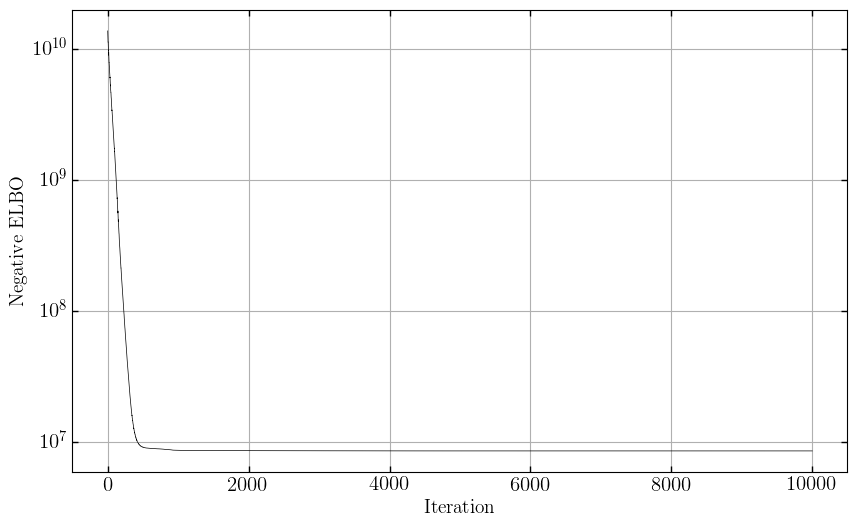

In [20]:
print(bkg_svi_results.losses[-1])
plt.figure(figsize=(10,6))
plt.plot(bkg_svi_results.losses, lw=0.5)
plt.yscale("log")
# plt.xlim(0,2e3) ; #plt.ylim(1.4e6, 1.5e6)
plt.xlabel('Iteration') ; plt.ylabel('Negative ELBO')
plt.grid()
plt.show()

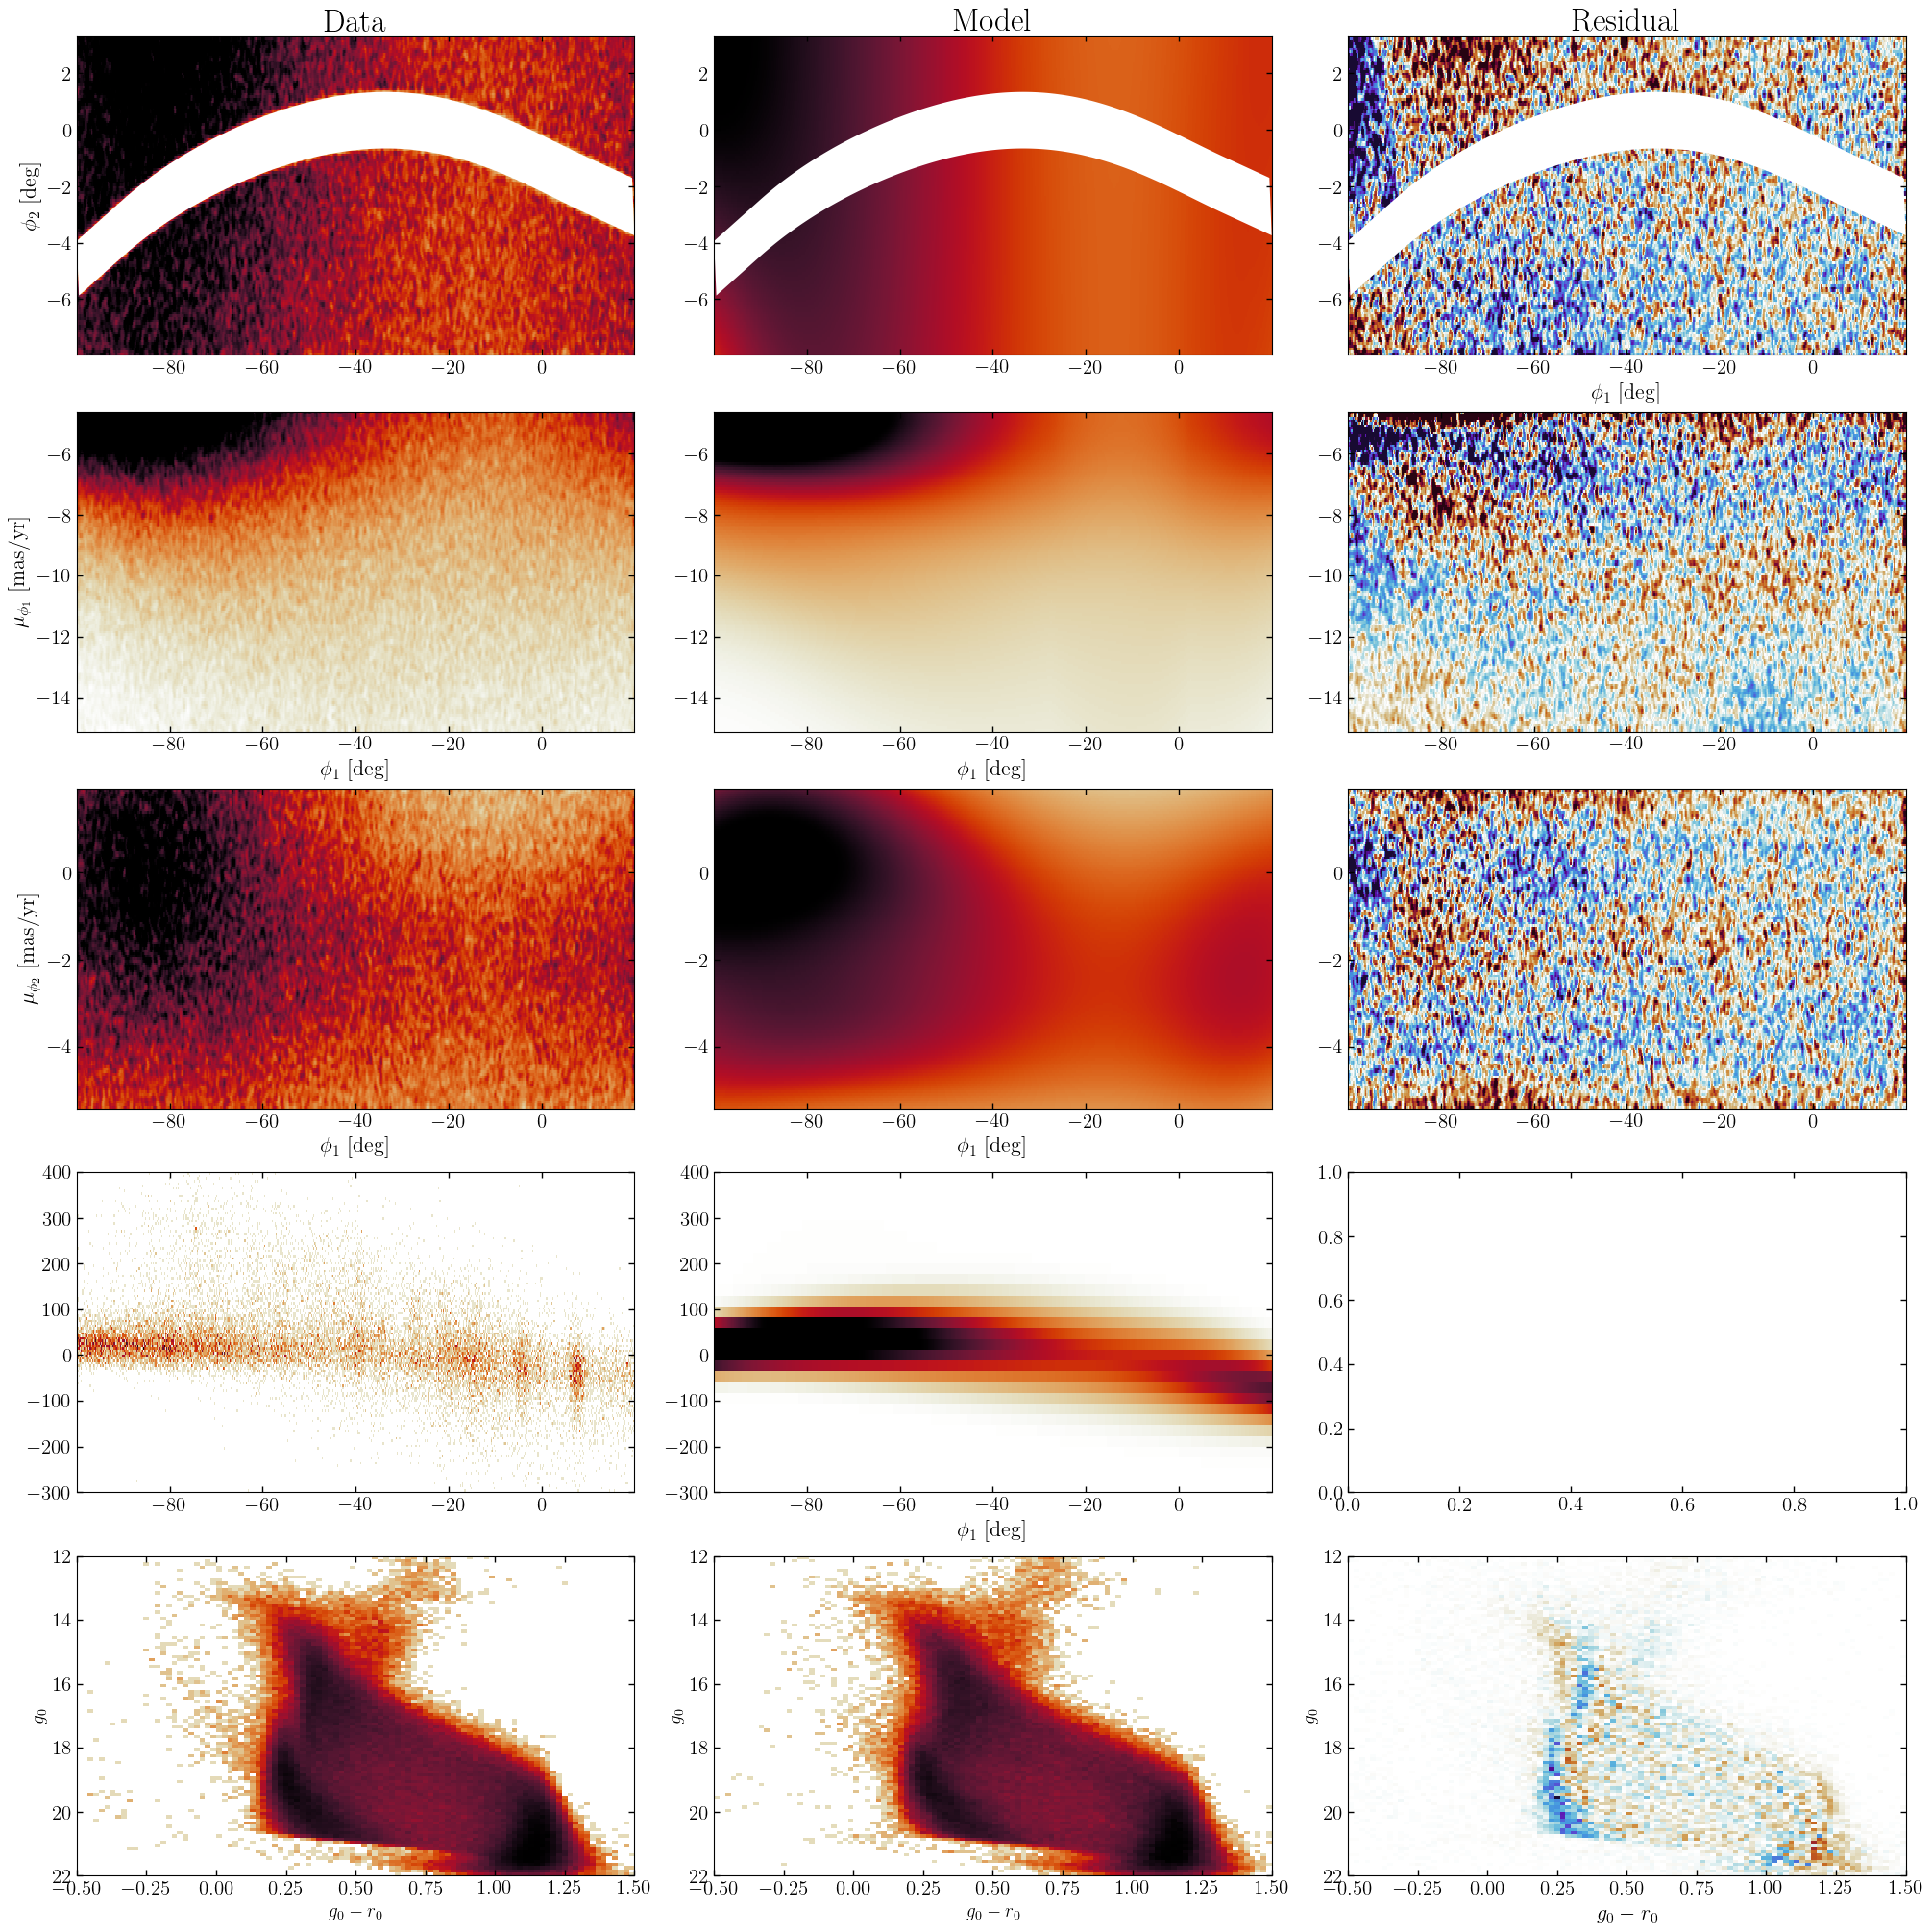

In [21]:
import matplotlib as mpl
# Diagnostics: kinematic projections (data vs. model) + a CMD panel (data vs.
# flow samples at the same phi1 values), for a quick visual sanity check.
fig, axes = plt.subplots(5, 3, figsize=(20, 20), constrained_layout=True)

axes = np.atleast_2d(axes)
plot_data_projections(
    data=bkg_data,
    grids=plot_grids,
    axes=axes[1, 0],
    pcolormesh_kwargs=dict(rasterized=True, vmax=20, vmin=0, cmap=CMAP),
    coord_names=[('phi1', 'pm1')]
)
plot_data_projections(
    data=bkg_data,
    grids=plot_grids,
    axes=[axes[0, 0], axes[2,0]],
    pcolormesh_kwargs=dict(rasterized=True, vmax=10, vmin=0, cmap=CMAP),
    coord_names=[('phi1', 'phi2'), ('phi1', 'pm2')]
)
axes[3,0].hist2d(bkg_data_['phi1'][bkg_data_['rv'] != 0], bkg_data_['rv'][bkg_data_['rv'] != 0], bins=[512, 128], 
                 range=[[phi1_lim[0],phi1_lim[1]], [-300,400]], cmap=CMAP)

bkg_model.plot_model_projections(ndata=len(bkg_data_), grids=plot_grids, grid_coord_names=[('phi1', 'pm1')],
                                 pars=bkg_params, axes=axes[1, 1], label=False,
                                 pcolormesh_kwargs=dict(rasterized=True, vmax=20, vmin=0, cmap=CMAP))
bkg_model.plot_model_projections(ndata=len(bkg_data_), grids=plot_grids, grid_coord_names=[('phi1', 'phi2'), ('phi1', 'pm2')],
                                 pars=bkg_params, axes=[axes[0, 1], axes[2,1]], label=False,
                                 pcolormesh_kwargs=dict(rasterized=True, vmax=10, vmin=0, cmap=CMAP))
bkg_model.plot_model_projections(ndata=len(bkg_data['rv'][bkg_data['rv']!=0]), grids=plot_grids, grid_coord_names=[('phi1', 'rv')],
                                 pars=bkg_params, axes=axes[3, 1], label=False,
                                 pcolormesh_kwargs=dict(rasterized=True, vmax=10, vmin=0, cmap=CMAP))

bkg_model.plot_residual_projections(
    grids=plot_grids, grid_coord_names=[('phi1', 'phi2')], 
    pars=bkg_params,
    data=run_data, axes=axes[0, 2], label=False, 
    pcolormesh_kwargs=dict(vmin=-2, vmax=2, cmap=cmr.fusion, rasterized=True)
)
bkg_model.plot_residual_projections(
    grids=plot_grids, grid_coord_names=[('phi1', 'pm1'), ('phi1', 'pm2')],
    pars=bkg_params, data=bkg_data, axes=axes[1:, 2], label=False, 
    pcolormesh_kwargs=dict(vmin=-2, vmax=2, cmap=cmr.fusion, rasterized=True)
)

axes[0, 0].set_title('Data', fontsize=24)
axes[0, 1].set_title('Model', fontsize=24)
axes[0, 2].set_title('Residual', fontsize=24)

flow_key, sample_key = jax.random.split(flow_key)
# NOTE: construct a *live* CalibratedFlowDensity directly here, rather
# than pulling the CMD term out of bkg_model.make_dists(bkg_params) --
# once cmd_flow/cmd_norm_stats are passed to make_bkg_model_component,
# that term is swapped to a FrozenLogProb (precomputed log_probs only,
# for SVI performance -- see initialize_stream.make_bkg_model_component),
# which has no .sample(). This is functionally identical for diagnostic
# purposes since the pretrained flow weights are frozen either way.
cmd_dist = CalibratedFlowDensity(flow=cmd_flow, norm_stats=cmd_norm_stats, x=bkg_data["phi1"])
cmd_flow_samples = jax.vmap(lambda k, x: cmd_dist.sample(k, x=x))(
    jax.random.split(sample_key, len(bkg_data['phi1'])), bkg_data["phi1"]
)

H1, xe, ye, = np.histogram2d(bkg_data_["g0"]-bkg_data_["r0"], bkg_data_["g0"], bins=100, range=[[-0.5,1.5], [12, 22]])
H2, _, _    = np.histogram2d(cmd_flow_samples[:, 0] - cmd_flow_samples[:, 1], cmd_flow_samples[:, 0], bins=100, range=[[-0.5,1.5], [12, 22]])
resid = H1-H2
vmax = np.nanmax(np.abs(resid))
axes[4, 0].pcolormesh(xe, ye, H1.T, norm=mpl.colors.LogNorm(), cmap=CMAP, rasterized=True)
axes[4, 1].pcolormesh(xe, ye, H2.T, norm=mpl.colors.LogNorm(), cmap=CMAP, rasterized=True)
axes[4, 2].pcolormesh(xe, ye, resid.T, cmap=cmr.fusion, vmin=-vmax, vmax=vmax, rasterized=True)

for ax in axes[4, :]:
    ax.set_xlabel(r"$g_0-r_0$")
    ax.set_ylabel(r"$g_0$")
    ax.invert_yaxis()

axes[3,0].set_ylim(-300, 400) ; axes[3,1].set_ylim(-300, 400)

with open('../../data/post_cats_data_flow_version.pkl', 'rb') as input_file_:
    post_cats = pickle.load(input_file_)
iso_obj = post_cats['iso_obj']
blank = cmr.take_cmap_colors(CMAP, N=2, return_fmt='hex')[0]
for ax in axes[0,:]:
    patch_sky = mpl.patches.Polygon(
            iso_obj.pawprint.skyprint["stream"].vertices[::50],
            facecolor=blank,
            alpha=1
        )
    ax.add_patch(patch_sky)

plt.show()

## TODO: get data again without the cut on Gaia G-mag. It's introducing an artificial boundary in the CMD that is difficult to model. We will just need to account for the selection function, but we were going to need to do that anyway. 

## Question: How good should our normalizing flow be? How good was it for the Starkman+24 paper?


## Stage 2: Stream model

Now includes the fixed single-stellar-population (SSP) isochrone CMD term
(`IsochroneCMD`, conditional on `stream_isochrone` having been loaded above)
in addition to `phi1, phi2, pm1, pm2, rv`. Uses the current
`make_stream_model_component` signature, which requires `rv_min`/`rv_max`
computed from the stream data's radial-velocity coverage.


In [35]:

rv_min = jnp.min(stream_data["phi1"][stream_data_err["rv"] != 1e4])
rv_max = jnp.max(stream_data["phi1"][stream_data_err["rv"] != 1e4])

stream_filename = SVI_RESULTS_DIR / "stream_{}_{}_{}_{}_{}_auto_normal.pkl".format(*STREAM_KNOT_SPACINGS)

stream_model = init_stream.make_stream_model_component(
    knot_spacings=STREAM_KNOT_SPACINGS, coord_bounds=coord_bounds, data=stream_data,
    rv_min=rv_min, rv_max=rv_max, stream_isochrone=stream_isochrone,
)

_d = None  # try_load_cached(stream_filename)
if _d is not None:
    print(f"Loaded cached stream SVI result from {stream_filename}")
    stream_svi_results, stream_guide = _d["svi_results"], _d["guide"]
else:
    stream_phi1_knots = stream_model.coord_parameters["phi1"]["locs"][0]
    stream_phi2_knots = stream_model.coord_parameters["phi2"]["knots"]
    stream_pm1_knots = stream_model.coord_parameters["pm1"]["knots"]
    stream_pm2_knots = stream_model.coord_parameters["pm2"]["knots"]
    stream_rv_knots = stream_model.coord_parameters["rv"]["knots"]

    _interp_dict = init_stream.interpolate_stream_tracks(stream_data, phi1_lim)
    eval_interp_phi2 = jnp.array(_interp_dict["phi2"](stream_phi2_knots)+2)
    eval_interp_pm1 = jnp.array(_interp_dict["pm1"](stream_pm1_knots)+2)
    eval_interp_pm2 = jnp.array(_interp_dict["pm2"](stream_pm2_knots)+2)
    eval_interp_rv = jnp.array(_interp_dict["rv"](stream_rv_knots)+2)

    stream_init_params = {
        "phi1": {
            "mixing_distribution": jnp.ones(len(stream_phi1_knots)) / len(stream_phi1_knots),
            "scales": jnp.full(stream_phi1_knots.shape[0], STREAM_KNOT_SPACINGS[0]),
        },
        "phi2": {"loc_vals": eval_interp_phi2, "scale_vals": jnp.full(stream_phi2_knots.shape[0], 0.5)},
        "pm1": {"loc_vals": eval_interp_pm1, "scale_vals": jnp.full(stream_pm1_knots.shape[0], 0.35)},
        "pm2": {"loc_vals": eval_interp_pm2, "scale_vals": jnp.full(stream_pm2_knots.shape[0], 0.35)},
        "rv": {"loc_vals": eval_interp_rv, "scale_vals": jnp.full(stream_rv_knots.shape[0], 4)},
    }

    

In [36]:
print(f"Fitting stream model ({NUM_STEPS['stream']} SVI steps)...")
stream_svi_results, stream_guide = run_SVI(
    stream_model, stream_init_params, stream_data, stream_data_err,
    num_steps=NUM_STEPS["stream"], adaptive_lr=True, init_lr=1e-2, num_particles=3,
)
# save_svi_result(stream_filename, stream_svi_results, stream_guide)

stream_params = get_svi_params(model=stream_model, data=stream_data, svi_results=stream_svi_results, guide=stream_guide)
print("final ELBO loss:", stream_svi_results.losses[-1])


Fitting stream model (20000 SVI steps)...


100%|██████████| 20000/20000 [01:21<00:00, 244.98it/s, init loss: 1246814735.6202, avg. loss [19001-20000]: 31332.7046]


final ELBO loss: 31333.776981675725


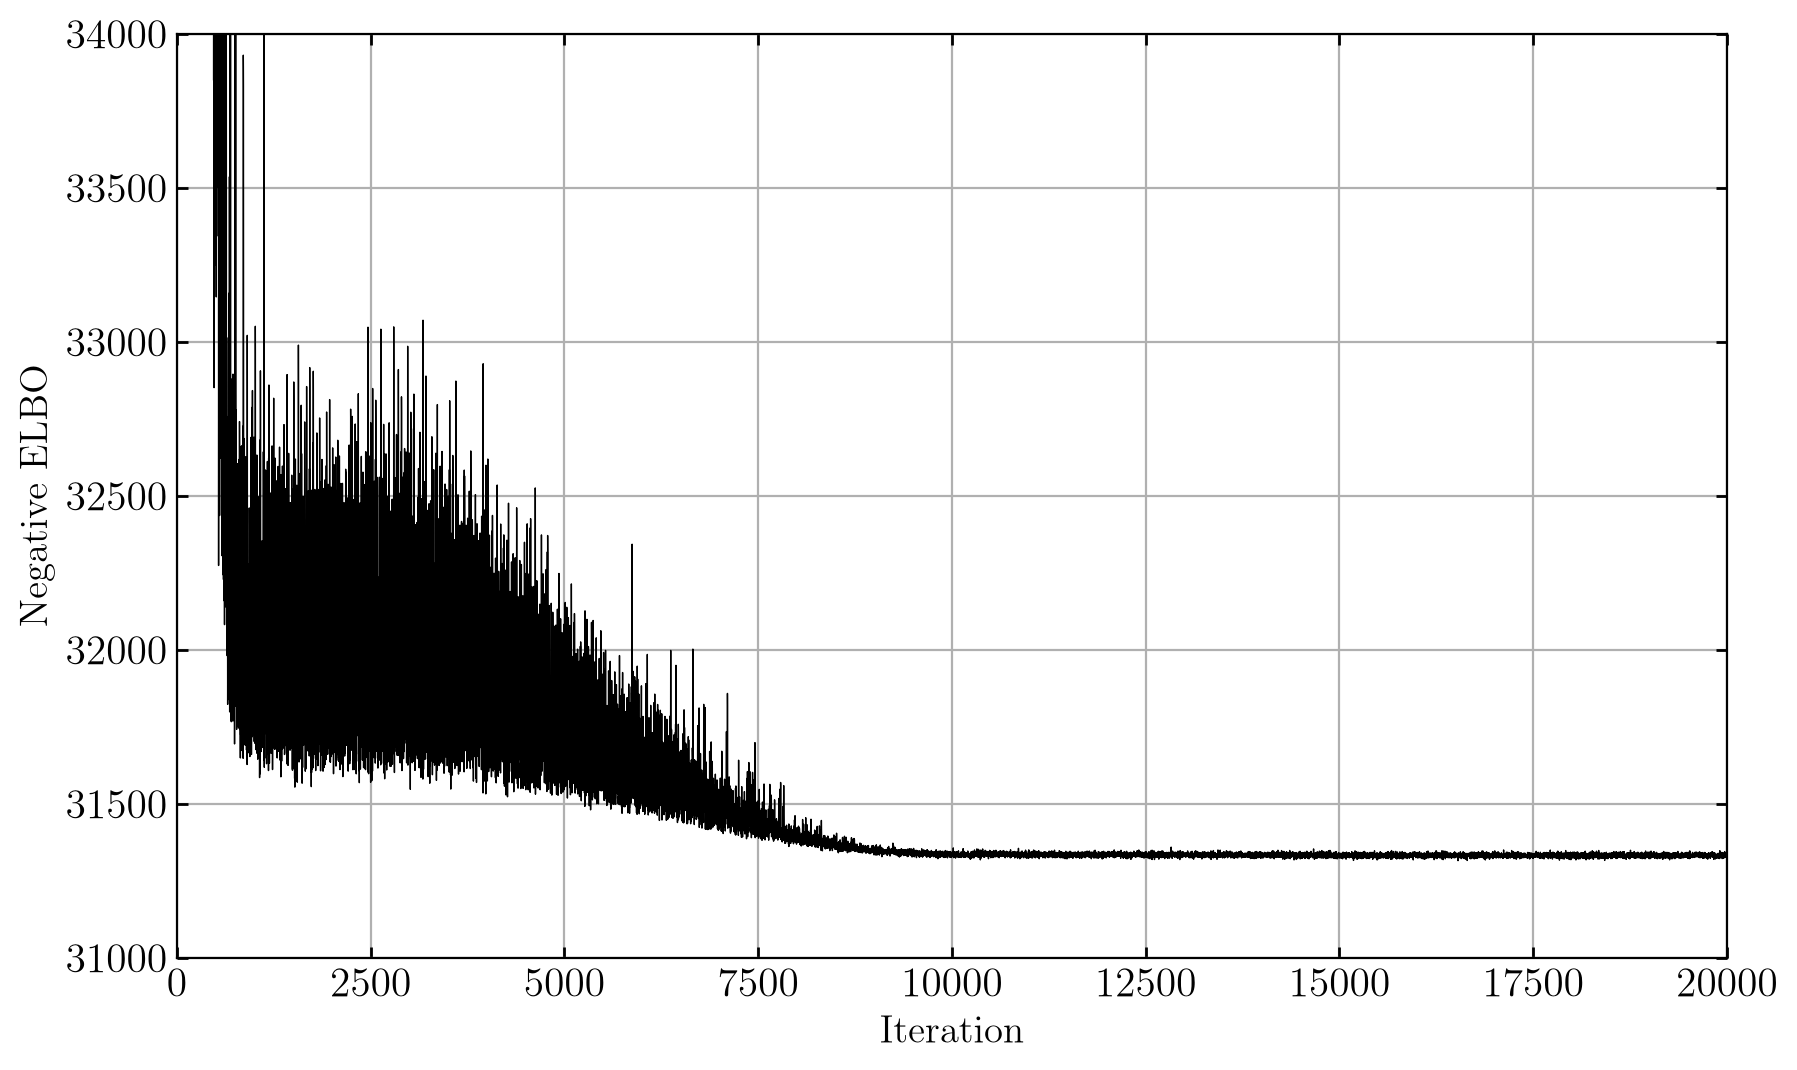

In [37]:
plt.figure(figsize=(10,6))
plt.plot(stream_svi_results.losses, lw=0.5)
# plt.yscale("log")
plt.xlim(0,2e4) ; plt.ylim(3.1e4, 3.4e4)
plt.xlabel('Iteration') ; plt.ylabel('Negative ELBO')
plt.grid()
plt.show()

/Users/Tavangar/Work/stream-membership/src/stream_membership/distributions/normal_spline.py:127: UserWarning: Out-of-support values provided to log prob method. The value argument should be within the support.
  return helper.log_prob(value)


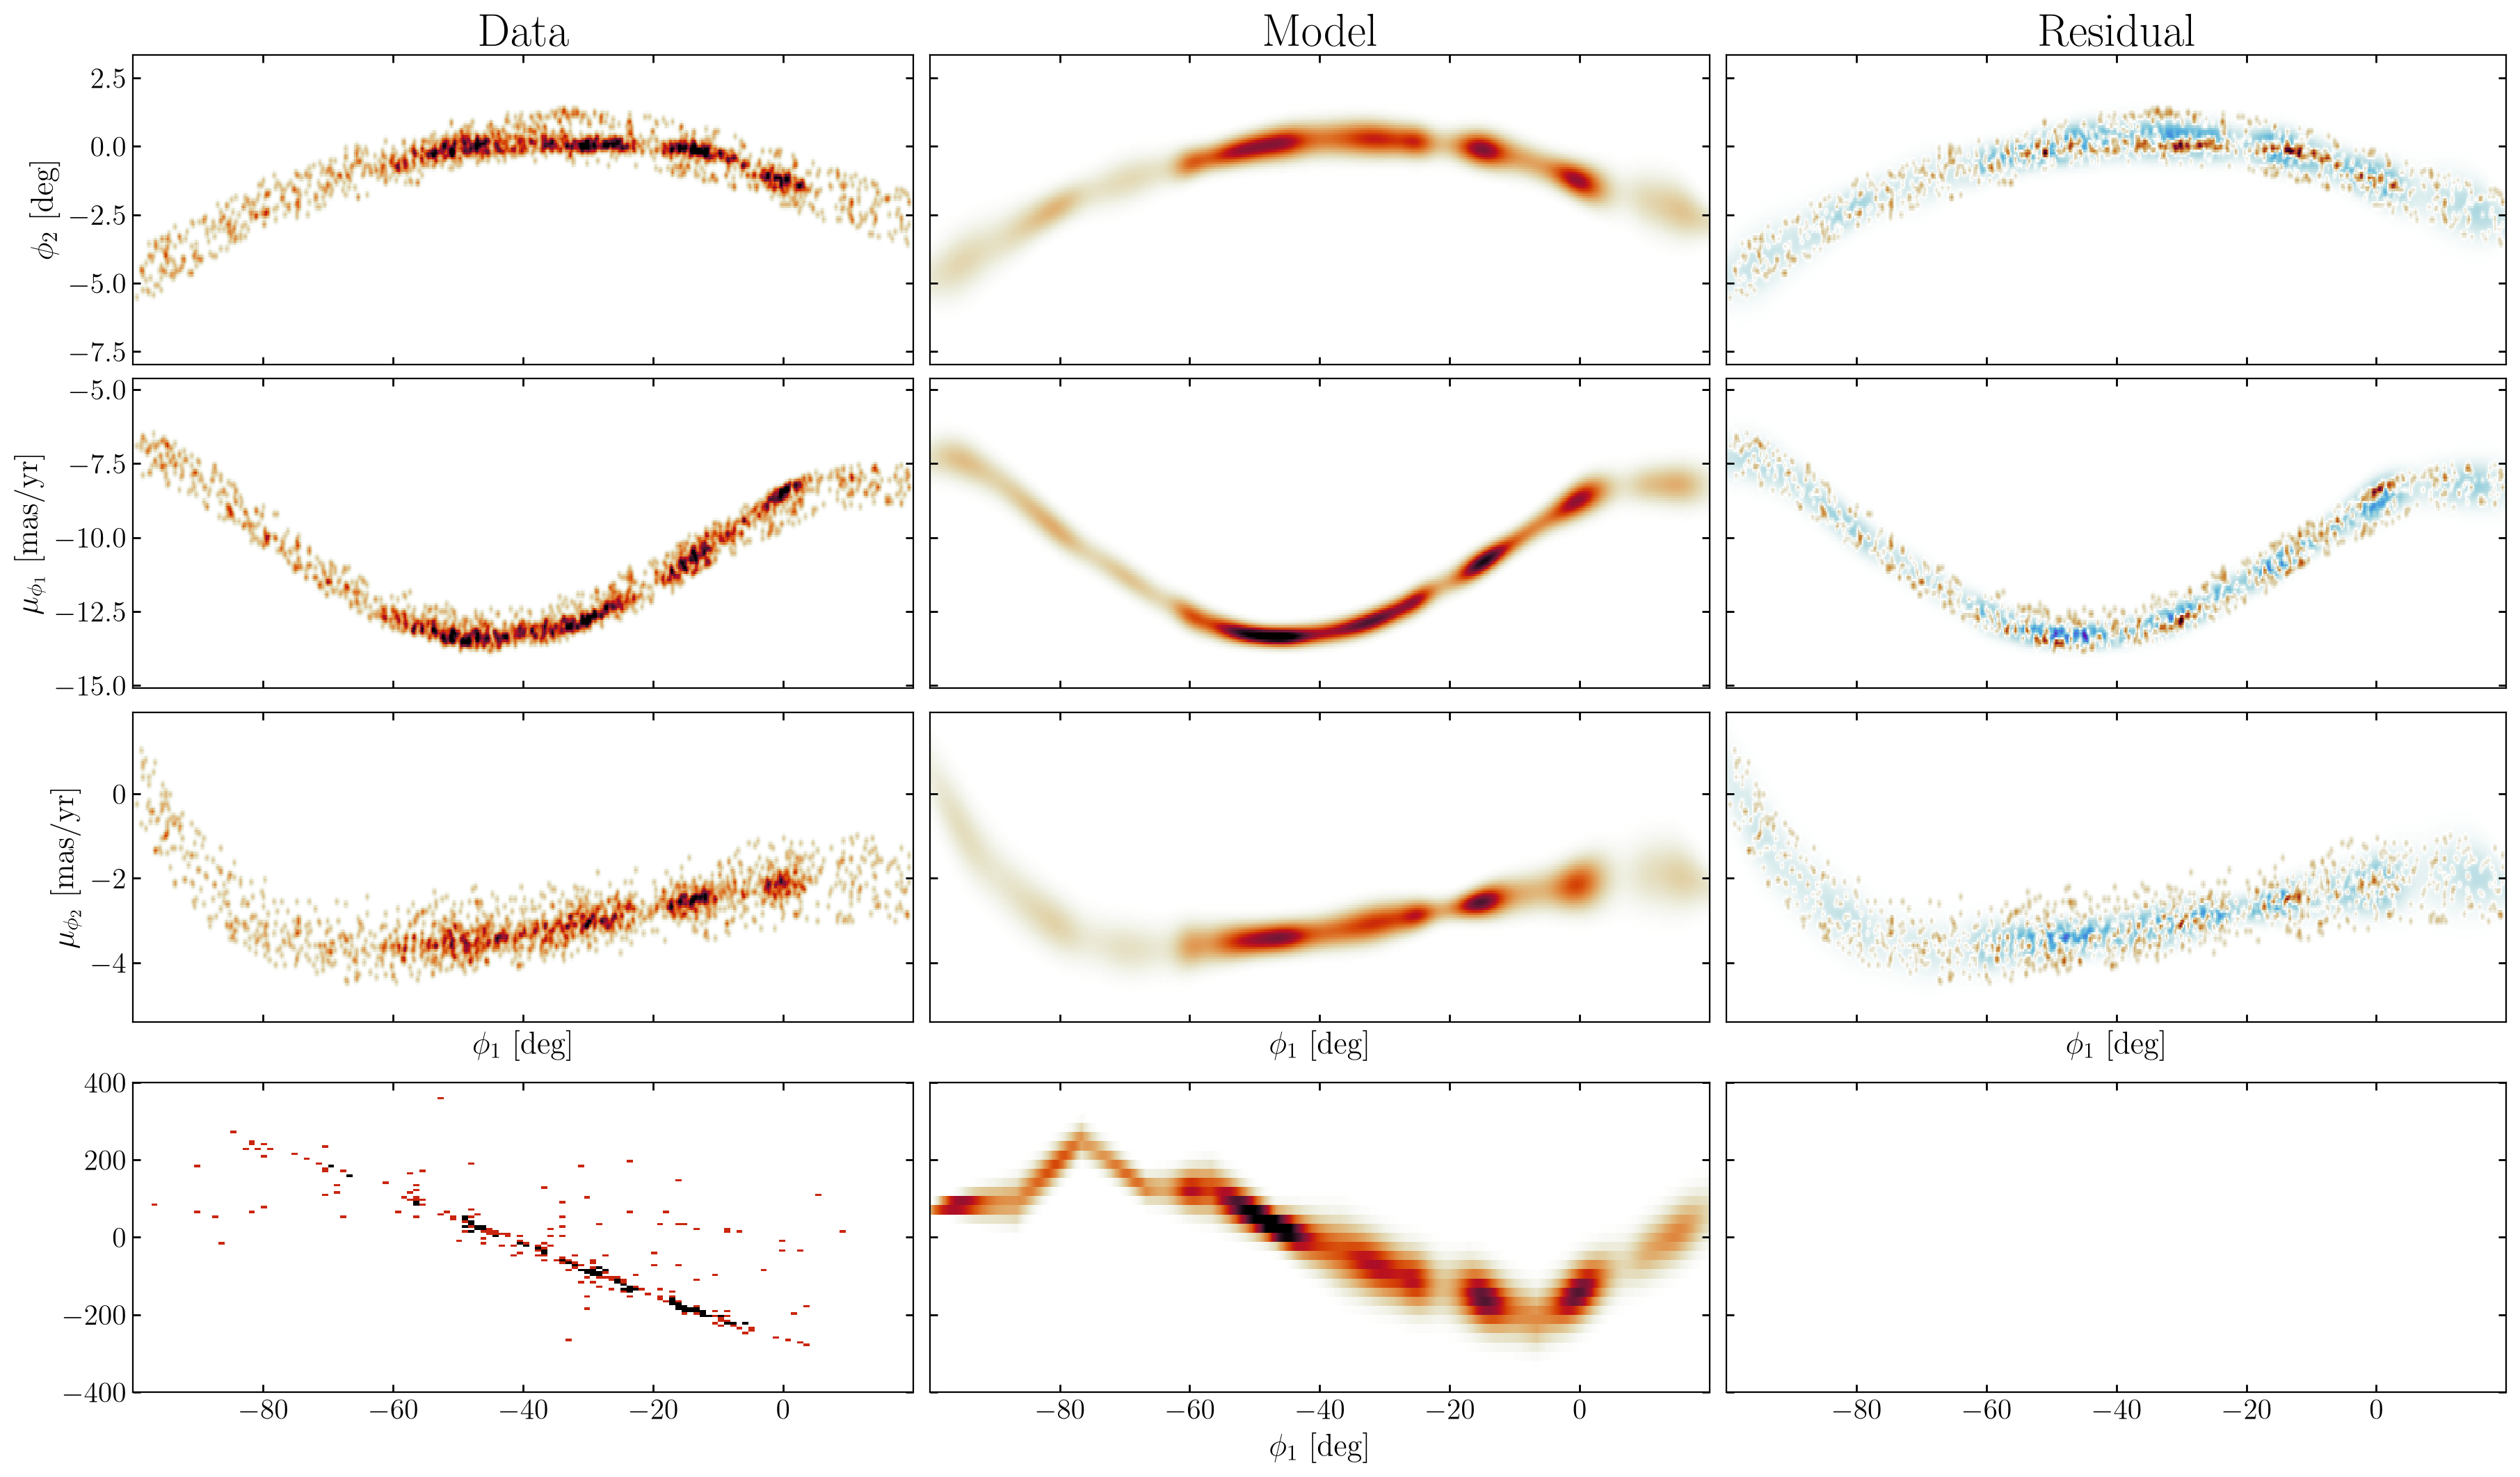

In [38]:

fig, axes = plt.subplots(
    4,
    3,
    figsize=(18, 3.5 * 3),
    sharex=True,
    sharey="row",
    constrained_layout=True,
)

axes = np.atleast_2d(axes)
plot_data_projections(
    data=stream_data,
    grids=plot_grids,
    coord_names=[('phi1','phi2'), ('phi1', 'pm1'), ('phi1', 'pm2')],
    axes=axes[:3, 0],
    pcolormesh_kwargs=dict(rasterized=True, vmax=1, vmin=0, cmap=CMAP)
    # coord_names=GD1BackgroundModel.coord_names,
)
axes[3,0].hist2d(stream_data_['phi1'][stream_data_['rv'] != 0], stream_data_['rv'][stream_data_['rv'] != 0], bins=[128, 128], 
                 range=[[phi1_lim[0],phi1_lim[1]], [-400,400]], cmap=CMAP, vmax=2, vmin=0)


stream_model.plot_model_projections(ndata=len(stream_data_), grids=plot_grids, grid_coord_names=[('phi1','phi2'), ('phi1', 'pm1'), ('phi1', 'pm2')],
                                    pars=stream_params, axes=axes[:3, 1], label=False,
                                     pcolormesh_kwargs=dict(rasterized=True, vmax=1, vmin=0, cmap=CMAP))
stream_model.plot_model_projections(ndata=len(stream_data_), grids=plot_grids, grid_coord_names=[('phi1','rv')],
                                    pars=stream_params, axes=axes[3, 1], label=False,
                                    pcolormesh_kwargs=dict(rasterized=True, vmax=2, vmin=0, cmap=CMAP))

stream_model.plot_residual_projections(
    grids=plot_grids, pars=stream_params, grid_coord_names=[('phi1','phi2'), ('phi1', 'pm1'), ('phi1', 'pm2')],
    data=stream_data, axes=axes[:3, 2], label=False, 
    pcolormesh_kwargs=dict(vmin=-1, vmax=1, cmap=RESID_CMAP, rasterized=True)
)
axes[3,0].set_ylim(-400, 400)
axes[0,0].set_title('Data', fontsize=24)
axes[0,1].set_title('Model', fontsize=24)
axes[0,2].set_title('Residual', fontsize=24)
plt.show()



### Stream CMD diagnostic

Visualizes the fitted `IsochroneCMD` term (see `scripts/plot_stream_cmd.py`):
the stream data's CMD with the fitted isochrone ridge line overlaid at a
few representative `phi1` values (showing the distance-modulus gradient
along the stream), the fitted vs. fixed Valluri+24 distance-modulus
track, and `IsochroneCMD` posterior samples vs. the real data as a sanity
check. No membership probabilities are available yet at this standalone
stage (`stream_data` is already a stream-only selection), so all points
are plotted un-colored/un-filtered.


In [39]:
import importlib
importlib.reload(sys.modules['plot_stream_cmd'])
from plot_stream_cmd import plot_stream_cmd_fit

In [40]:
cmd_dist = stream_model.make_dists(stream_params)[init_stream.CMD_COORD]

In [41]:
print(cmd_dist.dm_offset)
print(cmd_dist.color_offset)
print(cmd_dist.color_scale)

0.21756807326580394
0.09147164073221968
0.08603915826773359


In [42]:
print("track_abs_mag range:", cmd_dist.track_abs_mag.min(), cmd_dist.track_abs_mag.max())
print("track_color range:  ", cmd_dist.track_color.min(), cmd_dist.track_color.max())

# compare to what the data implies, at a representative phi1
dm0 = float(cmd_dist._distmod(jnp.asarray(0.0)))
print("implied dm at phi1=0:", dm0)
print("data abs mag range: ", (run_data_['g0'] - dm0).min(), (run_data_['g0'] - dm0).max())
print("data g-r range:   ", (run_data_['g0']-run_data_['r0']).min(), (run_data_['g0']-run_data_['r0']).max())

track_abs_mag range: -2.0634593415449647 13.083972300802305
track_color range:   0.06976682734143047 1.2119223002744217
implied dm at phi1=0: 15.197919635765805
data abs mag range:  -1015.5787558841637 12.794135318405376
data g-r range:    -1021.8947493359447 1022.0137809179723


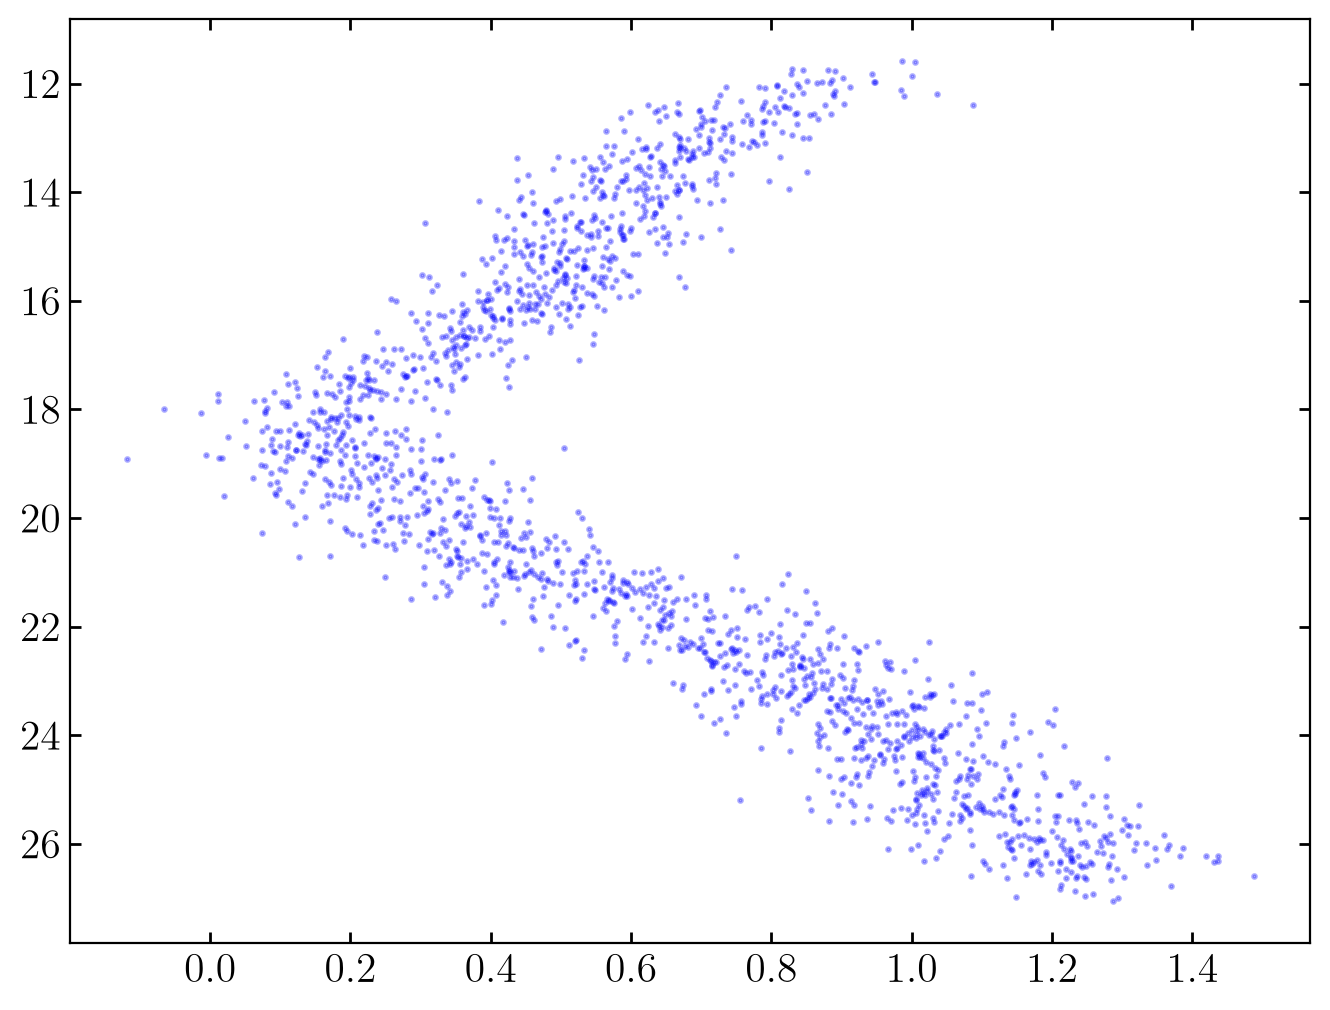

In [43]:
flow_key, sample_key = jax.random.split(flow_key)
cmd_flow_samples = jax.vmap(lambda k, x: cmd_dist.sample(k, x=x))(
    jax.random.split(sample_key, stream_data["phi1"].shape[0]), stream_data["phi1"]
)
plt.scatter(cmd_flow_samples[:, 0] - cmd_flow_samples[:, 1], cmd_flow_samples[:, 1], s=2, alpha=0.3, color="C1", rasterized=True)
plt.gca().invert_yaxis()
# plt.xlim(0,3)
# plt.ylim(-1,3)

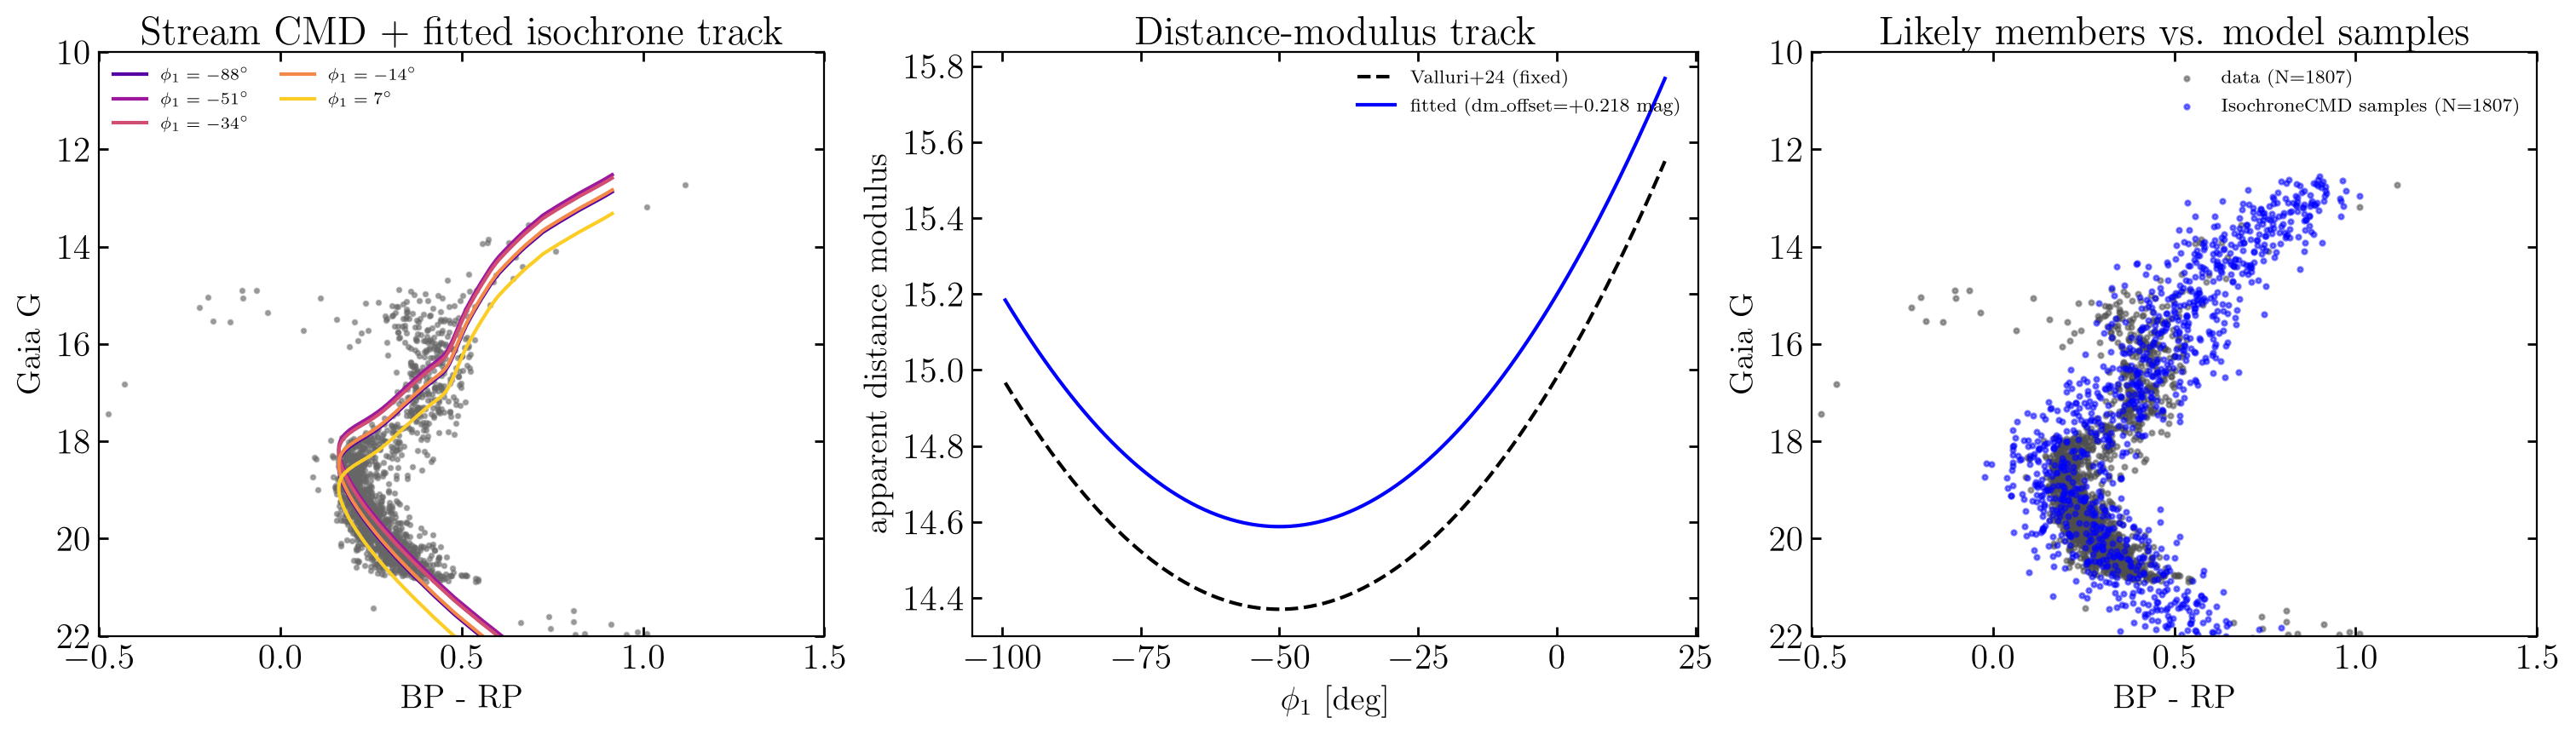

In [44]:

from plot_stream_cmd import plot_stream_cmd_fit

if stream_isochrone is not None:
    plot_stream_cmd_fit(stream_model, stream_params, stream_data)
    plt.show()
else:
    print("No stream_isochrone loaded -- skipping CMD diagnostic (see 'Load the stream SSP isochrone CMD track' above).")



## Stage 3: Background + stream mixture model

Refit jointly on `run_data` (the full candidate-member sample), starting
from the two single-component fits above.

**A note on memory (SMOKE_TEST sandboxes):** this stage (and Stage 4) JIT-
compile a substantially larger combined model than either single-component
fit above, since `ComponentMixtureModel` traces both components' log-
densities together. In a very memory-constrained environment (this
particular sandbox has ~4GB RAM and no swap), that compile step alone can
exceed available memory and get OOM-killed, even after shrinking the data,
`num_particles`, knot counts, and `N_MIXTURE` -- i.e. this is a hardware
ceiling in this specific sandbox, not a bug in the model-combination logic
itself (which is an unmodified port of the existing, working pattern in
`run_full_gd1_model.py` / `5-AutoNormal_SVI.ipynb`, and doesn't involve the
new CMD flow term at all -- see the note in the intro above). Stages 1-2
(which do exercise the new CMD flow term) were verified end-to-end in this
sandbox via `jupyter nbconvert --execute`. On your own machine (more RAM,
`HAVE_CATS=True`), Stages 3-4 should run the same way they already do in the
reference pipeline.


In [ ]:

bkg_stream_filename = SVI_RESULTS_DIR / "mm_bkg{}_{}_{}_{}_stream{}_{}_{}_{}_{}_auto_normal.pkl".format(
    *jnp.concatenate([BKG_KNOT_SPACINGS, STREAM_KNOT_SPACINGS])
)

# Both components now carry a CMD term over `("bp_rp", "phot_g_mean_mag")`
# -- the background's pretrained CMD flow (`cmd_flow`/`cmd_norm_stats`, as
# in Stage 1) and the stream's fixed SSP isochrone (`stream_isochrone`, as
# in Stage 2) -- so `ComponentMixtureModel`'s requirement that every
# component share the same `coord_names` (see
# `stream_membership.model.ComponentMixtureModel.__post_init__`) is
# satisfied and the CMD term can be included in this joint fit too. If
# `stream_isochrone` is None (no cached isochrone JSON -- see the "Load the
# stream SSP isochrone CMD track" cell above), the stream model simply omits
# CMD_COORD, and `bkg_model_mm` is built without its CMD term either so the
# two components still match.
bkg_model_mm = init_stream.make_bkg_model_component(
    knot_spacings=BKG_KNOT_SPACINGS, n_mixture=N_MIXTURE, coord_bounds=coord_bounds, data=run_data,
    **(dict(cmd_flow=cmd_flow, cmd_norm_stats=cmd_norm_stats) if stream_isochrone is not None else {}),
)
stream_model_mm = init_stream.make_stream_model_component(
    knot_spacings=STREAM_KNOT_SPACINGS, coord_bounds=coord_bounds, data=run_data,
    rv_min=rv_min, rv_max=rv_max, stream_isochrone=stream_isochrone,
)
stream_bkg_mm = ComponentMixtureModel(
    dist.Dirichlet(jnp.array([1.0, 1.0])), components=[bkg_model_mm, stream_model_mm]
)

_d = try_load_cached(bkg_stream_filename)
if _d is not None:
    print(f"Loaded cached background+stream SVI result from {bkg_stream_filename}")
    no_off_svi_results, no_off_guide = _d["svi_results"], _d["guide"]
else:
    f_stream = jnp.around(len(stream_data_) / len(run_data_), 3)

    filtered_bkg = {k: v for k, v in bkg_params.params.items() if "modeldata" not in k}
    filtered_stream = {k: v for k, v in stream_params.params.items() if "modeldata" not in k}
    packed_params = filtered_bkg | filtered_stream
    packed_params["mixture-probs"] = jnp.array([1 - f_stream, f_stream])
    # Note: `mixture:modeldata_*` is a bookkeeping/nuisance site introduced by
    # ComponentMixtureModel itself (not present in either single-component
    # fit, since those were fit as standalone ModelComponents). We don't set
    # it explicitly here -- numpyro's `init_to_value` falls back to its
    # default init strategy for any site missing from `init_params`, which is
    # fine for a nuisance site like this one. (run_full_gd1_model.py's `main`
    # instead seeds it from a previously cached full-mixture fit, which this
    # notebook doesn't assume exists.)

    print(f"Fitting background+stream mixture model ({NUM_STEPS['bkg_stream']} SVI steps)...")
    no_off_svi_results, no_off_guide = run_SVI(
        stream_bkg_mm, packed_params, run_data, run_data_err,
        num_steps=NUM_STEPS["bkg_stream"], adaptive_lr=True, init_lr=5e-4, num_particles=3,
    )
    save_svi_result(bkg_stream_filename, no_off_svi_results, no_off_guide)

no_off_params = get_svi_params(model=stream_bkg_mm, data=run_data, svi_results=no_off_svi_results, guide=no_off_guide)
print("final ELBO loss:", no_off_svi_results.losses[-1])
print("fitted mixture-probs [bkg, stream]:", no_off_params["mixture-probs"])


/var/folders/f1/wqzqbly11d9__jf5mjckhwvm0000gp/T/ipykernel_8987/150370654.py:24: UserWarning: Using `field(init=False)` on `equinox.Module` can lead to surprising behaviour
when used around `jax.grad`. In the following example, observe how JAX computes
gradients with respect to the `.len` attribute (which is a PyTree leaf passed
across the `jax.grad` boundary) and that there are no gradients with respect to
`.a` or `.b`:

```
import equinox as eqx
import jax
import jax.numpy as jnp

class Foo(eqx.Module):
    a: jax.Array
    b: jax.Array
    len: jax.Array = eqx.field(init=False)

    def __post_init__(self):
        self.len = jnp.sqrt(self.a**2 + self.b**2)

    def __call__(self, x):
        return self.len * x

@jax.jit
@jax.grad
def call(module, x):
    return module(x)

grads = call(Foo(jnp.array(3.0), jnp.array(4.0)), 5)
# Foo(
#   a=Array(0., dtype=float32, weak_type=True),
#   b=Array(0., dtype=float32, weak_type=True),
#   len=Array(5., dtype=float32, weak_type=True)
# )
```

NameError: name 'bkg_svi_results' is not defined


## Stage 4: Full mixture model (background + stream + offtrack)

Adds the spatial "offtrack" component -- a grid of 2D Gaussians in
`(phi1, phi2)` sharing the stream's proper-motion/RV distributions -- to
capture stream stars that scatter off the main track. Its `pm1`/`pm2`/`rv`
priors are re-centered (tightly) around the background+stream fit above,
rather than tied directly, since we don't expect these to vary continuously
enough to justify the spline parameterization used elsewhere.


In [21]:

full_filename = SVI_RESULTS_DIR / "full_mm_bkg{}_{}_{}_{}_stream{}_{}_{}_{}_{}_off{}_{}_auto_normal.pkl".format(
    *jnp.concatenate([BKG_KNOT_SPACINGS, STREAM_KNOT_SPACINGS, OFFTRACK_DX])
)

offtrack_model, offtrack_phi12_locs = init_stream.make_offtrack_model_component(OFFTRACK_DX, stream_model_mm, coord_bounds)

offtrack_model.coord_parameters["pm1"]["loc_vals"] = dist.TruncatedNormal(
    loc=no_off_params["stream"]["pm1"]["loc_vals"], scale=no_off_params["stream"]["pm1"]["scale_vals"],
    low=no_off_params["stream"]["pm1"]["loc_vals"] - 3 * no_off_params["stream"]["pm1"]["scale_vals"],
    high=no_off_params["stream"]["pm1"]["loc_vals"] + 3 * no_off_params["stream"]["pm1"]["scale_vals"],
)
offtrack_model.coord_parameters["pm2"]["loc_vals"] = dist.TruncatedNormal(
    loc=no_off_params["stream"]["pm2"]["loc_vals"], scale=no_off_params["stream"]["pm2"]["scale_vals"],
    low=no_off_params["stream"]["pm2"]["loc_vals"] - 3 * no_off_params["stream"]["pm2"]["scale_vals"],
    high=no_off_params["stream"]["pm2"]["loc_vals"] + 3 * no_off_params["stream"]["pm2"]["scale_vals"],
)
offtrack_model.coord_parameters["rv"]["loc_vals"] = dist.TruncatedNormal(
    loc=no_off_params["stream"]["rv"]["loc_vals"], scale=no_off_params["stream"]["rv"]["scale_vals"],
    low=no_off_params["stream"]["rv"]["loc_vals"] - 3 * no_off_params["stream"]["rv"]["scale_vals"],
    high=no_off_params["stream"]["rv"]["loc_vals"] + 3 * no_off_params["stream"]["rv"]["scale_vals"],
)
offtrack_model.coord_parameters["pm1"]["scale_vals"] = dist.TruncatedNormal(
    loc=no_off_params["stream"]["pm1"]["scale_vals"], scale=no_off_params["stream"]["pm1"]["scale_vals"] / 3,
    low=0, high=2 * no_off_params["stream"]["pm1"]["scale_vals"],
)
offtrack_model.coord_parameters["pm2"]["scale_vals"] = dist.TruncatedNormal(
    loc=no_off_params["stream"]["pm2"]["scale_vals"], scale=no_off_params["stream"]["pm2"]["scale_vals"] / 3,
    low=0, high=2 * no_off_params["stream"]["pm2"]["scale_vals"],
)
offtrack_model.coord_parameters["rv"]["scale_vals"] = dist.TruncatedNormal(
    loc=no_off_params["stream"]["rv"]["scale_vals"], scale=no_off_params["stream"]["rv"]["scale_vals"] / 3,
    low=0, high=2 * no_off_params["stream"]["rv"]["scale_vals"],
)
offtrack_model.coord_parameters["pm1"]["x"] = run_data["phi1"]
offtrack_model.coord_parameters["pm2"]["x"] = run_data["phi1"]
offtrack_model.coord_parameters["rv"]["x"] = run_data["phi1"]

mm = ComponentMixtureModel(
    dist.Dirichlet(jnp.array([1.0, 1.0, 1.0])),
    components=[bkg_model_mm, stream_model_mm, offtrack_model],
)
print(f"Offtrack grid: {len(offtrack_phi12_locs)} nodes, spacing={OFFTRACK_DX}")


Offtrack grid: 390 nodes, spacing=[3 1]


/var/folders/f1/wqzqbly11d9__jf5mjckhwvm0000gq/T/ipykernel_94786/2416212251.py:38: UserWarning: Using `field(init=False)` on `equinox.Module` can lead to surprising behaviour
when used around `jax.grad`. In the following example, observe how JAX computes
gradients with respect to the `.len` attribute (which is a PyTree leaf passed
across the `jax.grad` boundary) and that there are no gradients with respect to
`.a` or `.b`:

```
import equinox as eqx
import jax
import jax.numpy as jnp

class Foo(eqx.Module):
    a: jax.Array
    b: jax.Array
    len: jax.Array = eqx.field(init=False)

    def __post_init__(self):
        self.len = jnp.sqrt(self.a**2 + self.b**2)

    def __call__(self, x):
        return self.len * x

@jax.jit
@jax.grad
def call(module, x):
    return module(x)

grads = call(Foo(jnp.array(3.0), jnp.array(4.0)), 5)
# Foo(
#   a=Array(0., dtype=float32, weak_type=True),
#   b=Array(0., dtype=float32, weak_type=True),
#   len=Array(5., dtype=float32, weak_type=True)
# )
`

In [22]:

_d = try_load_cached(full_filename)
if _d is not None:
    print(f"Loaded cached full-mixture SVI result from {full_filename}")
    full_svi_results, full_guide = _d["svi_results"], _d["guide"]
else:
    _init_prob = jnp.ones(len(offtrack_phi12_locs))
    _init_prob /= _init_prob.sum()

    offtrack_init_params = {
        ("phi1", "phi2"): {
            "mixing_distribution": _init_prob,
            "scales": jnp.array([OFFTRACK_DX] * len(offtrack_phi12_locs)).T,
        },
        "pm1": no_off_params["stream"]["pm1"],
        "pm2": no_off_params["stream"]["pm2"],
        "rv": no_off_params["stream"]["rv"],
    }

    stream_prob = no_off_params["mixture-probs"][-1]
    off_prob = 0.25 * stream_prob
    bkg_prob = 1 - stream_prob - off_prob

    filtered_no_off = {k: v for k, v in no_off_svi_results.params.items() if not k.startswith("mixture")}
    mm_packed_params = filtered_no_off | mm.pack_params({"offtrack": offtrack_init_params})
    mm_packed_params["mixture-probs"] = jnp.array([bkg_prob, stream_prob, off_prob])
    for k in ("mixture:modeldata_auto_loc", "mixture:modeldata_auto_scale"):
        if k in no_off_svi_results.params:
            mm_packed_params[k] = no_off_svi_results.params[k]

    print(f"Fitting full mixture model with offtrack ({NUM_STEPS['full']} SVI steps)...")
    full_svi_results, full_guide = run_SVI(
        mm, mm_packed_params, run_data, run_data_err,
        num_steps=NUM_STEPS["full"], adaptive_lr=True, init_lr=1e-5, num_particles=3,
    )
    save_svi_result(full_filename, full_svi_results, full_guide)

full_params = get_svi_params(model=mm, data=run_data, svi_results=full_svi_results, guide=full_guide)
print("final ELBO loss:", full_svi_results.losses[-1])
print("fitted mixture-probs [bkg, stream, offtrack]:", full_params["mixture-probs"])


Fitting full mixture model with offtrack (20000 SVI steps)...


TypeError: max got incompatible shapes for broadcasting: (2, 1, 1), (83735, 2, 1).

In [ ]:

fig, ax = plt.subplots(1, 1, figsize=(10, 3))
plot_data_projections(
    data=run_data, grids=plot_grids, axes=ax,
    coord_names=[("phi1", "phi2")],
    pcolormesh_kwargs=dict(rasterized=True, cmap="gray_r", alpha=0.7),
)
ax.scatter(offtrack_phi12_locs[:, 0], offtrack_phi12_locs[:, 1], s=8, c="red", label="offtrack nodes")
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(full_svi_results.losses)
plt.xlabel("SVI step")
plt.ylabel("ELBO loss")
plt.title("Full mixture model SVI convergence")
plt.show()



### Full-mixture stream CMD diagnostic (membership-colored)

Same `plot_stream_cmd_fit` panels as in Stage 2, but now using the
Stage 4 full-mixture fit: `compute_membership_probs` turns the fitted
`mm` + `full_params` into per-star membership probabilities (a proper
softmax-normalized mixture responsibility, using the existing
`run_full_gd1_model.make_lp_dict` machinery, which already supports the
`IsochroneCMD` term for free). The CMD scatter is colored by
`p(stream)`, and the "likely members vs. model samples" panel is
restricted to stars with `p(stream) > 0.5`.


In [ ]:

from plot_stream_cmd import compute_membership_probs, plot_stream_cmd_fit

if stream_isochrone is not None:
    membership = compute_membership_probs(mm, run_data, run_data_err, full_params)
    plot_stream_cmd_fit(
        stream_model_mm, full_params["stream"], run_data,
        membership_probs=membership["stream"],
    )
    plt.show()

    print(f"N(p(stream) > 0.5) = {int((membership['stream'] > 0.5).sum())} / {len(run_data['phi1'])}")
else:
    print("No stream_isochrone loaded -- skipping CMD diagnostic (see 'Load the stream SSP isochrone CMD track' above).")



## Summary

Cached SVI results for each stage are written to `svi_results/` under
`ROOT_DIR`, keyed by knot spacing (so rerunning this notebook with the same
`BKG_KNOT_SPACINGS` / `STREAM_KNOT_SPACINGS` / `OFFTRACK_DX` picks up the
cached fits instead of refitting). Delete the relevant `.pkl` file (or change
the spacings) to force a refit of a given stage.

**CMD terms:** the background (pretrained normalizing flow) and stream
(fixed SSP isochrone, `IsochroneCMD`) both now have a CMD term, and both are
included throughout, including the Stage 3/4 joint mixtures. The offtrack
component reuses the stream's `IsochroneCMD` term directly (see
`make_offtrack_model_component` in `scripts/initialize_stream.py`), since
offtrack stars are physically stream stars that have scattered spatially off
the main track, and `ComponentMixtureModel` requires every mixture component
to share the same coordinates. If `data/stream_isochrone_gaia.json` isn't
found (see the isochrone-loading cell above), all of this gracefully
degrades to no CMD term anywhere in the pipeline, rather than a partial/
mismatched state.

**Next steps / things intentionally out of scope here:**

- `generate_stream_isochrone.py` needs to be run once on a machine with
  normal internet access (to download the MIST grid data), with the
  resulting `data/stream_isochrone_gaia.json` copied back here -- it cannot
  be generated inside this sandbox (see that script's module docstring).
- On your machine (`HAVE_CATS = True`), set `SMOKE_TEST = False` to run the
  full-length production fit (this notebook's `NUM_STEPS` defaults then match
  `scripts/run_full_gd1_model.py`'s CLI defaults).
- For a production CMD flow (rather than the quick/proxy one trained
  automatically above if missing), run
  `python scripts/pretrain_bkg_cmd_flow.py --data data/GD1-region-alldata.fits --out data/bkg_cmd_flow`
  directly, ideally pointed at the real `bkg_data_` selection rather than the
  proxy selection it uses by default (see that script's module docstring).
